# 17 — Insumos para fijar τ con la referencia en inglés

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`15-jss-screen-de-modelos-openkos.ipynb`](15-jss-screen-de-modelos-openkos.ipynb) ·
[protocolo de alineación](../docs/protocols/alignment.md) (v2.0) ·
[ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md) ·
[ADR 0011](../docs/decisions/0011-adr-alineacion-rol-e-intervalos-del-experimento-a.md) ·
issue #142

---

## Qué se pregunta aquí

El Experimento A mide cuántas decisiones de la referencia encuentra la extracción automática.
Para contar un acierto hace falta un umbral, **τ**: dos textos se consideran «la misma decisión» si
su similitud es al menos τ. Ni el ADR 0011 ni el notebook 15 lo fijan; ambos informan la curva
completa. Además, el protocolo v2.0 cambió el texto de referencia a su traducción al inglés, lo que
desplaza toda la curva, de modo que τ debe fijarse **después** de esa traducción.

Este notebook reúne dos evidencias para que jss decida: (A) **hasta dónde llega el azar**: desde qué τ
una salida que no corresponde a la reunión deja de «acertar», y (B) **desde dónde un juez** que
no es parte de la extracción **dice que la mayoría de los pares aceptados son la misma decisión**.
No decide: propone `max(τ_nulo, τ_juez)` y deja abierta la elección.

## Un ejemplo concreto

Tres pares reales emparejados por el puntaje, uno por región de similitud, con el veredicto del juez
(se generan en la sección 3.4; se transcriben aquí para tener el panorama desde el inicio):

| Similitud | Extraído | Referencia (inglés) | Juez |
|---|---|---|---|
| 0,576 | *Prototype colour limitation: The team acknowledged that the prototype uses a limited range of colours because the casing is designed to be interchangeable.* | *interchangeable case: have interchangeable cases* | sí |
| 0,724 | *chip type: The product will use the simple chip without an LCD, which means it will have push buttons instead of scroll buttons.* | *push buttons: since there is no LCD, they stick with the decision to use push buttons* | sí |
| 0,850 | *slogan placement: The company slogan will be placed on the back of the remote.* | *slogan: Engrave the company slogan on the back of the remote* | sí |

El primer par es discutible; los dos últimos lo son menos. La pregunta es dónde, a lo largo de la
similitud, los pares dejan de ser dudosos.

> **Qué es esto y qué no es.** Es un análisis versionado sobre las corridas ya guardadas del *screen*
> de modelos (`reports/experiment-a/model-screen-openkos/`), sin extracciones nuevas. El τ definitivo
> se escribe en un ADR **después** de que jss decida, apoyado en este análisis.
>
> **Límites.** ES2015 y TS3009 son series de **desarrollo**: ninguna cifra de este notebook entra en
> una tabla de resultados (ADR 0005). Son 27 y 26 decisiones de referencia y dos equipos; los pares de
> la muestra comparten decisiones de referencia y textos entre modelos y corridas, así que no son
> independientes entre sí. El juez es un modelo, no una persona.


## Glosario

Los términos técnicos establecidos se mantienen tal cual; cada uno se explica aquí.

| Término | Qué significa en este notebook |
|---|---|
| τ | Umbral de similitud (entre 0 y 1). Un par extraída–referencia cuenta como coincidencia si la similitud coseno de sus *embeddings* (`bge-m3`) es al menos τ. Con τ bajo se acepta casi cualquier parecido; con τ alto, solo textos casi iguales. |
| Referencia | Las decisiones de cada serie anotadas por personas y adjudicadas (*ground truth*). Las etiquetas humanas están en español; el texto que se compara con las extracciones es su traducción automática al inglés ([protocolo de alineación](../docs/protocols/alignment.md) v2.0). |
| Cobertura (*recall*) | Aciertos divididos por las decisiones de referencia: qué parte de lo que había que encontrar se encontró. |
| Control nulo | Puntuar la salida de un equipo contra la referencia de otro: ningún acierto puede ser real, así que la cobertura que aparece mide solo parecido temático. |
| `τ_nulo` | Criterio A: el menor τ de la grilla en que la cobertura nula media es de 0,05 o menos. |
| Par emparejado | Una decisión extraída y la decisión de referencia con que la asignación uno a uno del puntaje (algoritmo húngaro, misma reunión) la empareja. |
| Bin | Tramo de 0,05 de similitud, por ejemplo [0,65; 0,70). |
| Juez | Un modelo de lenguaje de otra familia que los extractores (`gpt-oss:20b`, el juez de la tesis) al que se le muestran los dos textos de un par y responde sí o no a «¿describen la misma decisión?». |
| Intervalo de Wilson | Intervalo de confianza del 95 % para una proporción; es estable con pocas observaciones. |
| `τ_juez` | Criterio B: el menor límite inferior de bin desde el cual la proporción de «sí» del juez supera 0,5 en ese bin y en todos los superiores. |
| τ propuesto | `max(τ_nulo, τ_juez)`. Es una propuesta: la decisión es de jss. |


## Hoja de ruta

1. **Datos y método.** ¿Qué corridas y qué referencias se usan?
2. **Curvas con la referencia en inglés.** ¿Cuánto se desplaza la cobertura real al traducir la referencia?
3. **Control nulo y muestra juzgada.** ¿Desde qué τ el azar temático cae a casi cero (`τ_nulo`)? ¿Desde qué
   similitud la mayoría de los pares aceptados son la misma decisión (`τ_juez`)?
4. **Propuesta.** `max(τ_nulo, τ_juez)` y qué cobertura real deja cada τ candidato.
5. **Hallazgos.**
6. **Preguntas abiertas.**


## Reglas fijadas antes de mirar los resultados

Se fijaron antes de calcular ninguna cifra (documento de trabajo de la tarea, issue #142) y no se
modificaron después:

- **Datos.** Solo las corridas ya guardadas de `reports/experiment-a/model-screen-openkos/`
  (`screen/`, 5 corridas por modelo y serie, y `confirm/`, 15 corridas), series ES2015 y TS3009,
  con la referencia en inglés. No se genera ninguna extracción nueva.
- **Criterio A (control nulo).** Como en el notebook 15 (§6.2): la salida de una serie se puntúa
  contra la referencia de la otra, reunión a reunión, en los dos sentidos. `τ_nulo` es el menor τ de la
  grilla con cobertura nula media de 0,05 o menos.
- **Criterio B (juez).** Muestra de pares emparejados con similitud en [0,50; 0,90), estratificada en
  bins de 0,05, hasta 25 pares por bin, semilla fija, sin repetir textos idénticos. El juez
  (`gpt-oss:20b`) responde «¿describen ambos textos la misma decisión?» (sí/no) con un *prompt*
  versionado. `τ_juez` es el menor límite inferior de bin desde el cual la proporción de «sí» es mayor que
  0,5 en ese bin y en todos los superiores.
- **Propuesta.** τ = `max(τ_nulo, τ_juez)`; la curva completa se sigue informando.

**Precisiones de implementación** (la regla no las fija; se declaran para que sean revisables):

1. «Cobertura nula media» es el promedio de la cobertura de las 100 corridas puntuadas en nulo (40 del
   *screen* y 60 de la confirmatoria, en las dos series y los dos sentidos), con todas las corridas con el mismo peso.
   Se informa además la peor celda (modelo × serie) y el valor por fase.
2. Los pares se emparejan con τ = 0,50, el valor más bajo de la grilla y del rango muestreado, de modo que
   cualquier par que algún τ mayor pueda contar sea candidato. Con un τ mayor la asignación húngara puede elegir otros pares.
3. Los bins sin ninguna respuesta utilizable no cuentan en la regla de `τ_juez` (se omiten, no fallan).
4. Las respuestas del juez que no se pueden leer (formato inválido) no entran en la proporción y se cuentan aparte.
5. El orden en que el juez ve los dos textos (extraído primero o referencia primero) es aleatorio por par,
   con la misma semilla, para neutralizar el sesgo de posición.


---

# 1. Datos y método

**Qué se hace y por qué.** Se cargan las 100 corridas guardadas (40 del *screen* y 60 de la
confirmatoria), las dos referencias (español e inglés) y el modelo de similitud (`bge-m3`), para
puntuar con el mismo código del notebook 15 (`afg.experiments.model_screen`) y poder comparar.
Las corridas solo son de ES2015 y TS3009; el cargador rechaza cualquier otra serie.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from afg.conditions.c1_retrieval import OllamaEmbedder
from afg.evaluation.alignment_analysis import embedding_similarity
from afg.evaluation.judge import OllamaJudgeBackend
from afg.evaluation.judge_calibration_runner import load_think_settings
from afg.evaluation.reference import load_series_reference
from afg.experiments.model_screen import curve_summary, load_pass_runs, score_curve
from afg.experiments.tau_calibration import (
    BIN_WIDTH,
    PER_BIN,
    SAMPLE_HIGH,
    SAMPLE_LOW,
    JudgmentStore,
    bin_table,
    coverage_by_tau,
    digest_of,
    examples_by_region,
    installed_digests,
    judge_sample,
    matched_pairs,
    null_coverage,
    null_curve_points,
    propose_tau,
    reference_shift_table,
    stratified_sample,
    tau_judge,
    tau_null,
)
from afg.shared.config import load_experiments_config
from afg.shared.paths import AMI_DIR, EXPERIMENT_A_DIR, TRANSCRIPTS_DIR

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

SCREEN_DIR = EXPERIMENT_A_DIR / "model-screen-openkos"
CALIBRATION_DIR = EXPERIMENT_A_DIR / "tau-calibration"
SERIES = ("ES2015", "TS3009")
CONFIG = load_experiments_config()
TAU_GRID = CONFIG["alignment"]["tau_grid"]
SEED = CONFIG["shared_budget"]["seed"]
JUDGE_MODEL = CONFIG["judge"]["model"]
TABLE_TAUS = (0.60, 0.70, 0.80)
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"

for path in (SCREEN_DIR, AMI_DIR, TRANSCRIPTS_DIR):
    if not path.exists():
        raise SystemExit(f"No se encontro {path}.\nVer notebooks/README.md (Reproducibilidad).")

screen_runs = load_pass_runs(sorted((SCREEN_DIR / "screen").glob("runs-pass-*.json")))
confirm_runs = load_pass_runs(sorted((SCREEN_DIR / "confirm").glob("runs-pass-*.json")))
all_runs = screen_runs + confirm_runs

refs_en = {s: list(load_series_reference(s, language="en").decisions) for s in SERIES}
refs_es = {s: list(load_series_reference(s, language="es").decisions) for s in SERIES}

_embedder = OllamaEmbedder.from_config()
_cache: dict[str, list[float]] = {}


def embed(texts):
    missing = [t for t in dict.fromkeys(texts) if t not in _cache]
    if missing:
        _cache.update(zip(missing, _embedder.embed(missing), strict=True))
    return [_cache[t] for t in texts]


similarity = embedding_similarity(embed)

print(
    f"Corridas: screen {len(screen_runs)}, confirmatoria {len(confirm_runs)}; "
    f"decisiones de referencia { ({s: len(r) for s, r in refs_en.items()}) }"
)
print(f"Modelo de embeddings: {_embedder.model}; grilla de τ: {TAU_GRID}; semilla: {SEED}")

Corridas: screen 40, confirmatoria 60; decisiones de referencia {'ES2015': 27, 'TS3009': 26}
Modelo de embeddings: bge-m3; grilla de τ: [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]; semilla: 42


---

# 2. La curva real con la referencia en inglés

**Qué se hace y por qué.** Se puntúan las corridas con cada referencia para ver cuánto se desplaza la
cobertura al traducir la referencia. Interesa porque un τ elegido con la referencia en español no
valdría para la inglesa.

In [2]:
def curves(references, runs):
    return curve_summary(score_curve(runs, references, similarity, taus=TAU_GRID))


real_en = {"screen": curves(refs_en, screen_runs), "confirmatoria": curves(refs_en, confirm_runs)}
real_es = {"screen": curves(refs_es, screen_runs), "confirmatoria": curves(refs_es, confirm_runs)}

shift = pd.concat(
    [
        reference_shift_table(real_es[ph], real_en[ph], taus=TABLE_TAUS, metric="recall").assign(
            fase=ph
        )
        for ph in real_en
    ]
)
shift_table = shift.pivot_table(
    index=["fase", "series", "model"],
    columns="tau",
    values=["es", "en", "shift"],
).round(3)
shift_table

en                   es                shift              
tau                                     0.6    0.7    0.8    0.6    0.7    0.8    0.6    0.7    0.8
fase          series model                                                                         
confirmatoria ES2015 qwen3.6:27b      0.667  0.467  0.079  0.575  0.225  0.035  0.091  0.242  0.044
                     qwen3:8b         0.635  0.338  0.111  0.474  0.136  0.010  0.160  0.202  0.101
              TS3009 qwen3.6:27b      0.944  0.613  0.200  0.818  0.392  0.051  0.126  0.221  0.149
                     qwen3:8b         0.854  0.436  0.138  0.646  0.226  0.010  0.208  0.210  0.128
screen        ES2015 qwen3.6:27b      0.622  0.444  0.081  0.563  0.222  0.022  0.059  0.222  0.059
                     qwen3.6:35b-a3b  0.733  0.474  0.081  0.652  0.252  0.015  0.081  0.222  0.067
                     qwen3:14b        0.719  0.363  0.022  0.548  0.059  0.022  0.170  0.304  0.000
                     qwen3:8b         0.622  0.370  0.126  0.481  0.148  0.015  0.141  0.222  0.111
              TS3009 qwen3.6:27b      0.946  0.608  0.177  0.808  0.369  0.031  0.138  0.238  0.146
                     qwen3.6:35b-a3b  0.954  0.569  0.185  0.838  0.354  0.038  0.115  0.215  0.146
                     qwen3:14b        0.923  0.500  0.115  0.785  0.277  0.023  0.138  0.223  0.092
                     qwen3:8b         0.885  0.477  0.115  0.654  0.215  0.015  0.231  0.262  0.100

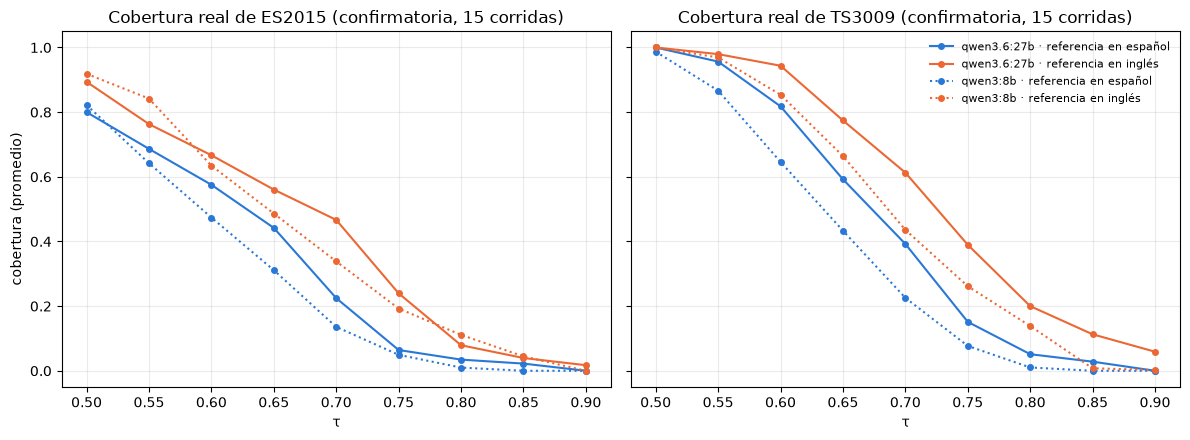

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, series in zip(axes, SERIES, strict=True):
    for model, style in (("qwen3.6:27b", "-"), ("qwen3:8b", ":")):
        for lang, table, color in (("español", real_es, BLUE), ("inglés", real_en, ORANGE)):
            d = table["confirmatoria"]
            d = d[(d.model == model) & (d.series == series)]
            ax.plot(
                d.tau,
                d.recall_mean,
                color=color,
                linestyle=style,
                marker="o",
                markersize=4,
                label=f"{model} · referencia en {lang}",
            )
    ax.set_title(f"Cobertura real de {series} (confirmatoria, 15 corridas)")
    ax.set_xlabel("τ")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("cobertura (promedio)")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Resultado — traducir la referencia sube la cobertura real en todo el tramo central de la curva; el mayor
desplazamiento es con τ = 0,70.**

En la confirmatoria (15 corridas), con τ = 0,60 la cobertura de `qwen3.6:27b` pasa de 0,575 a 0,667
en ES2015 y de 0,818 a 0,944 en TS3009; con τ = 0,70 pasa de 0,225 a 0,467 y de 0,392 a 0,613
(entre +0,20 y +0,24 en las cuatro combinaciones de modelo y serie); con τ = 0,80 de 0,035 a 0,079 y de
0,051 a 0,200. En `qwen3:8b` las cifras con τ = 0,70 son 0,136 → 0,338 (ES2015) y 0,226 → 0,436 (TS3009).
El *screen* (5 corridas, cuatro modelos) da el mismo patrón (+0,21 a +0,30 con τ = 0,70).
Con τ = 0,80 la cobertura sigue baja con la referencia inglesa (0,08 a 0,20 en `qwen3.6:27b`;
0,11 a 0,14 en `qwen3:8b`): la traducción levanta el techo, pero no lo elimina.


---

# 3. Control nulo y muestra juzgada

## 3.1 Criterio A: control nulo con la referencia en inglés

**Qué se hace y por qué.** Se puntúa la salida de una serie contra la referencia de la otra,
reunión a reunión (ES2015a con TS3009a, etc.), en los dos sentidos. Como ninguna decisión de un equipo
puede ser un acierto real para el otro, la cobertura que aparece es parecido temático (los dos
equipos diseñan un control remoto). `τ_nulo` es el menor τ de la grilla en que esa cobertura media
es de 0,05 o menos. Se muestra también con la referencia en español para ver el desplazamiento.

In [4]:
null_en_points = null_curve_points(all_runs, refs_en, similarity, taus=TAU_GRID)
null_es_points = null_curve_points(all_runs, refs_es, similarity, taus=TAU_GRID)
null_en = null_coverage(null_en_points)
null_es = null_coverage(null_es_points)
null_en_screen = null_coverage(null_curve_points(screen_runs, refs_en, similarity, taus=TAU_GRID))
null_en_confirm = null_coverage(null_curve_points(confirm_runs, refs_en, similarity, taus=TAU_GRID))

TAU_NULO = tau_null(null_en)
side = null_en.merge(null_es, on="tau", suffixes=(" (inglés)", " (español)"))[
    [
        "tau",
        "runs (inglés)",
        "recall_mean (inglés)",
        "recall_worst_cell (inglés)",
        "recall_mean (español)",
        "recall_worst_cell (español)",
    ]
].rename(
    columns={
        "tau": "τ",
        "runs (inglés)": "corridas",
        "recall_mean (inglés)": "nulo medio, ref. inglés",
        "recall_worst_cell (inglés)": "peor celda, ref. inglés",
        "recall_mean (español)": "nulo medio, ref. español",
        "recall_worst_cell (español)": "peor celda, ref. español",
    }
)
display(side.round(3))
print(f"τ_nulo (criterio A, referencia en inglés, 100 corridas): {TAU_NULO}")
print(f"τ_nulo con la referencia en español (solo comparación): {tau_null(null_es)}")
print(f"τ_nulo solo screen: {tau_null(null_en_screen)}")
print(f"τ_nulo solo confirmatoria: {tau_null(null_en_confirm)}")

,τ,corridas,"nulo medio, ref. inglés","peor celda, ref. inglés","nulo medio, ref. español","peor celda, ref. español"
0,0.50,100,0.948,0.998,0.905,0.963
1,0.55,100,0.831,0.915,0.655,0.765
2,0.60,100,0.570,0.631,0.321,0.371
3,0.65,100,0.285,0.363,0.132,0.237
4,0.70,100,0.138,0.188,0.045,0.112
5,0.75,100,0.053,0.100,0.011,0.027
6,0.80,100,0.015,0.035,0.003,0.015
7,0.85,100,0.004,0.009,0.001,0.007
8,0.90,100,0.001,0.008,0.000,0.000


τ_nulo (criterio A, referencia en inglés, 100 corridas): 0.8
τ_nulo con la referencia en español (solo comparación): 0.7
τ_nulo solo screen: 0.8
τ_nulo solo confirmatoria: 0.8


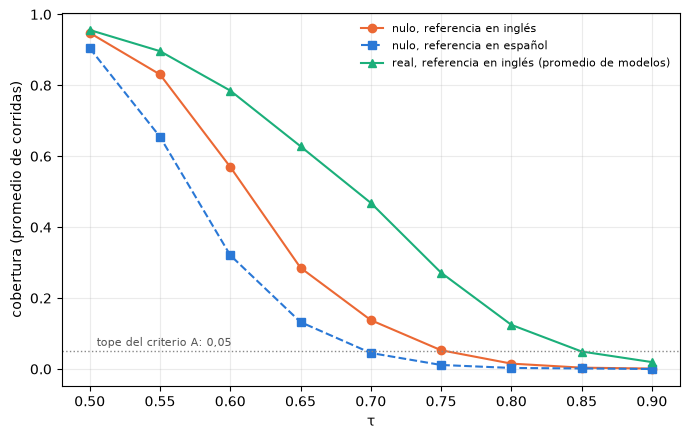

In [5]:
real_en_coverage = coverage_by_tau(score_curve(all_runs, refs_en, similarity, taus=TAU_GRID))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(
    null_en.tau, null_en.recall_mean, color=ORANGE, marker="o", label="nulo, referencia en inglés"
)
ax.plot(
    null_es.tau,
    null_es.recall_mean,
    color=BLUE,
    marker="s",
    linestyle="--",
    label="nulo, referencia en español",
)
ax.plot(
    real_en_coverage.tau,
    real_en_coverage.recall_mean,
    color=GREEN,
    marker="^",
    label="real, referencia en inglés (promedio de modelos)",
)
ax.axhline(0.05, color="#888888", linestyle=":", linewidth=1)
ax.text(0.505, 0.065, "tope del criterio A: 0,05", fontsize=8, color="#555555")
ax.set_xlabel("τ")
ax.set_ylabel("cobertura (promedio de corridas)")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Resultado — con la referencia en inglés el azar temático baja a casi cero recién con τ = 0,80, un paso
de la grilla más tarde que con la española (`τ_nulo` = 0,80 frente a 0,70).**

La cobertura nula media con la referencia inglesa es 0,570 con τ = 0,60, 0,138 con τ = 0,70, 0,053 con
τ = 0,75 y 0,015 con τ = 0,80; con la española, 0,321, 0,045, 0,011 y 0,003. La traducción también acerca la salida de un equipo
a la referencia del otro, y el piso sube. Esto
sustituye al «alrededor de 0,32 con τ = 0,60» del notebook 15, que era válido solo para la referencia en
español. Con τ = 0,75 la cobertura nula (0,053) queda a 0,003 del tope de 0,05: la regla
(≤ 0,05) da 0,80, pero la decisión es sensible a ese margen. La peor celda (modelo × serie)
con τ = 0,80 es 0,035, también bajo el tope, y `τ_nulo` es 0,80 tanto en el *screen* como en la
confirmatoria por separado.

## 3.2 Criterio B: muestra de pares y juez

**Qué se hace y por qué.** El control nulo mide el azar, pero no dice desde qué similitud un par
aceptado es de verdad la misma decisión. Para eso se toman los pares que el puntaje empareja
(asignación uno a uno, misma reunión) con similitud en [0,50; 0,90), se agrupan en bins de 0,05 y se
sortean hasta 25 por bin con la semilla del proyecto (42), sin repetir pares de textos idénticos. Un
juez de otra familia que los extractores, `gpt-oss:20b`, responde sí o no a «¿describen ambos
textos la misma decisión?». Cada respuesta cruda, el *hash* del *prompt* y el *digest* del modelo
quedan en `reports/experiment-a/tau-calibration/`
([`PROCEDENCIA.md`](../reports/experiment-a/tau-calibration/PROCEDENCIA.md)), y una nueva ejecución del
notebook reutiliza lo guardado sin volver a llamar al juez.

In [6]:
pool = matched_pairs(all_runs, refs_en, similarity, tau=SAMPLE_LOW)
sample = stratified_sample(pool, seed=SEED, per_bin=PER_BIN)
in_range = [p for p in pool if SAMPLE_LOW <= p.similarity < SAMPLE_HIGH]
print(f"Pares emparejados con τ = {SAMPLE_LOW:.2f}: {len(pool)}")
print(f"  con similitud en [{SAMPLE_LOW:.2f}; {SAMPLE_HIGH:.2f}): {len(in_range)}")
print(f"  textos distintos (extraído, referencia) en ese rango: {sum(sample.available.values())}")
print(
    f"  muestra: {len(sample.pairs)} pares, semilla {sample.seed}, hasta {sample.per_bin} por bin"
)
pd.DataFrame(
    {
        "bin": [f"[{b:.2f}; {b + BIN_WIDTH:.2f})" for b in sample.available],
        "pares distintos disponibles": list(sample.available.values()),
        "en la muestra": [sum(p.bin_low == b for p in sample.pairs) for b in sample.available],
    }
)

Pares emparejados con τ = 0.50: 2531
  con similitud en [0.50; 0.90): 2480
  textos distintos (extraído, referencia) en ese rango: 1848
  muestra: 200 pares, semilla 42, hasta 25 por bin


,bin,pares distintos disponibles,en la muestra
0,[0.50; 0.55),189,25
1,[0.55; 0.60),230,25
2,[0.60; 0.65),305,25
3,[0.65; 0.70),299,25
4,[0.70; 0.75),367,25
5,[0.75; 0.80),293,25
6,[0.80; 0.85),116,25
7,[0.85; 0.90),49,25


In [7]:
installed = installed_digests()
DIGEST = digest_of(JUDGE_MODEL, installed)
store = JudgmentStore(CALIBRATION_DIR)
already = len(store.load())
backend = OllamaJudgeBackend(think=load_think_settings())
judgments = judge_sample(
    sample.pairs,
    backend=backend,
    judge_model=JUDGE_MODEL,
    model_digest=DIGEST,
    seed=SEED,
    temperature=0.0,
    think=load_think_settings().get(JUDGE_MODEL),
    store=store,
)
meta = json.loads(store.meta_path.read_text(encoding="utf-8"))
print(f"Respuestas guardadas antes de esta ejecución: {already}; pares juzgados: {len(judgments)}")
print(f"Juez: {meta['judge_model']} (digest {meta['model_digest'][:19]})")
print(f"temperatura {meta['temperature']}, semilla {meta['seed']}, razonamiento {meta['think']!r}")
print(f"Prompt {meta['prompt_version']} (sha256 {meta['prompt_sha256'][:16]}…)")
print(f"fallas de formato: {meta['n_failures']}; llamadas: {meta['judge_seconds_total']:.0f} s")

Respuestas guardadas antes de esta ejecución: 200; pares juzgados: 200
Juez: gpt-oss:20b (digest f38aa0c53da5f8c49d0)
temperatura 0.0, semilla 42, razonamiento 'low'
Prompt same-decision-v1 (sha256 c34d5fc3eb80dc9c…)
fallas de formato: 0; llamadas: 1080 s


### 3.3 Proporción de «sí» por bin

**Qué se hace y por qué.** Se calcula, en cada bin, la proporción de pares que el juez considera la misma decisión,
con su intervalo de Wilson del 95 %, y se aplica la regla de `τ_juez`.

In [8]:
table = bin_table(judgments)
TAU_JUEZ = tau_judge(table)
shown = table.assign(
    bin=[f"[{lo:.2f}; {hi:.2f})" for lo, hi in zip(table.bin_low, table.bin_high, strict=True)]
)[["bin", "n", "yes", "rate", "ci_low", "ci_high", "failures"]].rename(
    columns={
        "yes": "sí",
        "rate": "proporción de sí",
        "ci_low": "IC95 inf.",
        "ci_high": "IC95 sup.",
        "failures": "fallas",
    }
)
display(shown.round(3).reset_index(drop=True))
print(f"τ_juez (criterio B): {TAU_JUEZ}")

,bin,n,sí,proporción de sí,IC95 inf.,IC95 sup.,fallas
0,[0.50; 0.55),25,3,0.12,0.042,0.300,0
1,[0.55; 0.60),25,6,0.24,0.115,0.434,0
2,[0.60; 0.65),25,7,0.28,0.143,0.476,0
3,[0.65; 0.70),25,8,0.32,0.172,0.516,0
4,[0.70; 0.75),25,20,0.80,0.609,0.911,0
5,[0.75; 0.80),25,19,0.76,0.566,0.885,0
6,[0.80; 0.85),25,23,0.92,0.750,0.978,0
7,[0.85; 0.90),25,23,0.92,0.750,0.978,0


τ_juez (criterio B): 0.7


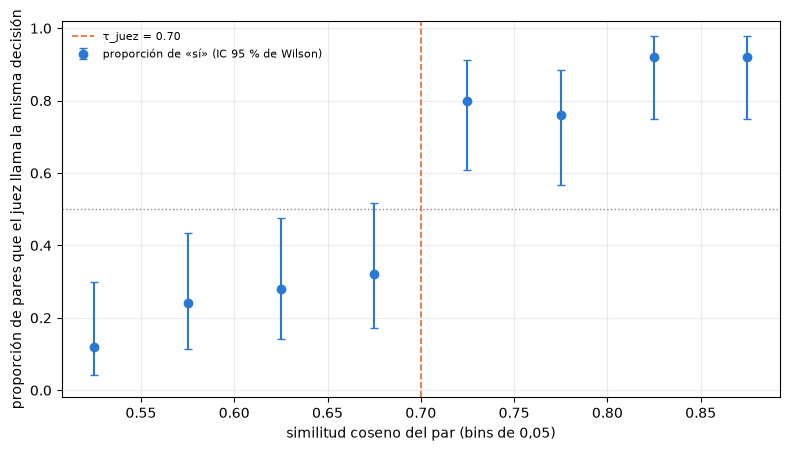

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
mid = table.bin_low + BIN_WIDTH / 2
ax.errorbar(
    mid,
    table.rate,
    yerr=[table.rate - table.ci_low, table.ci_high - table.rate],
    fmt="o",
    color=BLUE,
    capsize=3,
    label="proporción de «sí» (IC 95 % de Wilson)",
)
ax.axhline(0.5, color="#888888", linestyle=":", linewidth=1)
if TAU_JUEZ is not None:
    ax.axvline(
        TAU_JUEZ, color=ORANGE, linestyle="--", linewidth=1.2, label=f"τ_juez = {TAU_JUEZ:.2f}"
    )
ax.set_xlabel("similitud coseno del par (bins de 0,05)")
ax.set_ylabel("proporción de pares que el juez llama la misma decisión")
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

### 3.4 Un par real por región de similitud

**Qué se hace y por qué.** Se muestra, en tres regiones de similitud, el par más cercano al centro de la región
con el veredicto del juez y su razón, para que se vea qué significa cada región.

In [10]:
REGIONS = ((0.50, 0.65), (0.65, 0.80), (0.80, 0.90))
rows = []
for (lo, hi), (_, _, j) in zip(
    REGIONS, examples_by_region(judgments, regions=REGIONS), strict=False
):
    rows.append(
        {
            "región": f"[{lo:.2f}; {hi:.2f})",
            "similitud": round(j.pair.similarity, 3),
            "extraído": j.pair.extracted_text,
            "referencia (inglés)": j.pair.reference_text,
            "juez": "sí" if j.same else "no",
            "razón del juez": j.rationale,
        }
    )
for r in rows:
    print("\n".join(f"{k}: {v}" for k, v in r.items()) + "\n")

región: [0.50; 0.65)
similitud: 0.576
extraído: Prototype colour limitation: The team acknowledged that the prototype uses a limited range of colours because the casing is designed to be interchangeable.
referencia (inglés): interchangeable case: have interchangeable cases
juez: sí
razón del juez: Both texts commit to using interchangeable cases; Text B explains the resulting colour limitation as a consequence of that decision.

región: [0.65; 0.80)
similitud: 0.724
extraído: chip type: The product will use the simple chip without an LCD, which means it will have push buttons instead of scroll buttons.
referencia (inglés): push buttons: since there is no LCD, they stick with the decision to use push buttons
juez: sí
razón del juez: Both texts commit to using push buttons for the product; Text B adds that this is because a simple chip without an LCD will be used, but it does not change the choice of push buttons.

región: [0.80; 0.90)
similitud: 0.85
extraído: slogan placement: The comp

**Resultado — el juez dice «misma decisión» en menos de un tercio de los pares por debajo de 0,70 y en
al menos tres cuartos desde 0,70; `τ_juez` = 0,70.**

La proporción de «sí» es 0,12, 0,24, 0,28 y 0,32 en los cuatro bins desde 0,50 hasta 0,70, y 0,80, 0,76,
0,92 y 0,92 en los cuatro siguientes. Los intervalos de Wilson de [0,65; 0,70) (0,17 a 0,52) y
[0,70; 0,75) (0,61 a 0,91) no se solapan: el salto es real dentro de la muestra, y no hay un tramo gris de
bins cercanos al 0,5. Las 200 respuestas fueron legibles (0 fallas de formato) y las llamadas tardaron
1.080 s en total. Es una muestra de 25 pares por bin sacada de 1.848 pares de textos distintos
(2.480 emparejamientos en el rango); el bin [0,85; 0,90) tenía solo 49 pares distintos.
Hay que leerlo como la opinión de un modelo sobre una muestra: el primer ejemplo de la sección
3.4 (0,576) es un «sí» discutible, de modo que no se puede asumir que el juez sea tan estricto como una
persona, y no se sabe cuánto coincidiría con una anotación humana.

---

# 4. Propuesta: `max(τ_nulo, τ_juez)`

**Qué se hace y por qué.** Se aplica la regla prerregistrada y se mira qué cobertura real
deja cada τ candidato, para que la decisión de jss se tome sabiendo lo que cuesta.

In [11]:
PROPOSED = propose_tau(TAU_NULO, TAU_JUEZ)
print(f"τ_nulo = {TAU_NULO}; τ_juez = {TAU_JUEZ}; propuesta = max(τ_nulo, τ_juez) = {PROPOSED}")
tau_of_interest = sorted({round(t, 2) for t in (TAU_NULO, TAU_JUEZ, PROPOSED) if t is not None})
rows = []
for model in ("qwen3.6:27b", "qwen3:8b"):
    for series in SERIES:
        for tau in tau_of_interest:
            d = real_en["confirmatoria"]
            d = d[(d.model == model) & (d.series == series) & ((d.tau - tau).abs() < 1e-9)].iloc[0]
            rows.append(
                {
                    "modelo": model,
                    "serie": series,
                    "τ": tau,
                    "cobertura real": round(d.recall_mean, 3),
                    "F1 real": round(d.f1_mean, 3),
                    "cobertura nula (todos)": round(
                        float(null_en[(null_en.tau - tau).abs() < 1e-9].recall_mean.iloc[0]), 3
                    ),
                }
            )
pd.DataFrame(rows)

τ_nulo = 0.8; τ_juez = 0.7; propuesta = max(τ_nulo, τ_juez) = 0.8


,modelo,serie,τ,cobertura real,F1 real,cobertura nula (todos)
0,qwen3.6:27b,ES2015,0.7,0.467,0.381,0.138
1,qwen3.6:27b,ES2015,0.8,0.079,0.064,0.015
2,qwen3.6:27b,TS3009,0.7,0.613,0.356,0.138
3,qwen3.6:27b,TS3009,0.8,0.200,0.116,0.015
4,qwen3:8b,ES2015,0.7,0.338,0.207,0.138
5,qwen3:8b,ES2015,0.8,0.111,0.068,0.015
6,qwen3:8b,TS3009,0.7,0.436,0.204,0.138
7,qwen3:8b,TS3009,0.8,0.138,0.065,0.015


**Resultado — la regla propone τ = 0,80, pero con ese τ la cobertura real de ambos modelos baja a 0,08 a 0,20.**

`τ_nulo` = 0,80 y `τ_juez` = 0,70, así que la propuesta es **0,80**: lo manda el control nulo, no el juez.
Con τ = 0,70 la cobertura real de `qwen3.6:27b` es de 0,467 en ES2015 y 0,613 en TS3009 (la de `qwen3:8b`,
0,338 y 0,436) frente a una cobertura nula de 0,138; con τ = 0,80 es de 0,079 y 0,200 (`qwen3:8b`, 0,111 y 0,138)
frente a 0,015. Con τ = 0,80 el azar prácticamente desaparece, pero el instrumento también casi deja
de encontrar decisiones reales, y los pares entre 0,70 y 0,80, que el juez aprueba en 39 de 50 casos, quedarían
fuera. Con τ = 0,70 los pares aceptados son mayoritariamente la misma decisión, pero el 13,8 % de la
cobertura de una salida ajena también contaría. Los dos criterios, aplicados tal como se fijaron, no
coinciden, y la elección entre ellos es una decisión de jss.

---

# 5. Hallazgos

1. **La referencia en inglés desplaza toda la curva.** La cobertura real de la confirmatoria sube entre
   +0,20 y +0,24 con τ = 0,70 y hasta +0,15 con τ = 0,80 en las cuatro combinaciones de modelo y serie.
2. **El piso del azar también sube.** La cobertura nula media con τ = 0,60 es 0,570 (0,321 con la
   referencia en español) y solo baja de 0,05 con τ = 0,80 (0,70 con la española). `τ_nulo` = 0,80.
3. **El juez separa con nitidez.** Menos de un tercio de «sí» por debajo de 0,70 y 0,76 a 0,92 desde
   0,70; `τ_juez` = 0,70, con intervalos que no se solapan en el salto.
4. **Los dos criterios proponen τ distintos y la propuesta (0,80) deja poca cobertura real.**
   Con τ = 0,80 la cobertura real de `qwen3.6:27b` es de 0,08 a 0,20.
5. **La cobertura absoluta es sensible a τ.** Una cifra de cobertura del Experimento A sin su τ
   y sin su piso nulo no se puede interpretar; sigue siendo necesario informar la curva completa.


---

# 6. Preguntas abiertas

**Qué se hace y por qué.** Se dejan planteadas las preguntas que los datos abren; este notebook no
decide, y la elección del τ principal corresponde a jss.

1. **¿Qué τ principal se fija?** Dos criterios válidos dan 0,70 (juez) y 0,80 (control nulo). Con 0,80
   se cumplen los dos, pero casi no queda cobertura real; con 0,70 el juez está de acuerdo, pero el azar
   temático aún aporta 0,138 de cobertura. ¿Se prioriza no contar azar o no perder decisiones reales?
   Una vía intermedia es 0,75: el azar vale 0,053, justo sobre el tope de 0,05.
2. **¿Es el tope de 0,05 del control nulo una regla o un criterio de lectura?** Con 0,75 se pasa por
   0,003; con una regla algo distinta (por ejemplo, la peor celda en lugar del promedio) el resultado
   cambia. ¿Se mantiene el tope tal como se fijó?
3. **Validación manual del protocolo.** El protocolo de alineación (paso 3) exige contrastar el
   emparejamiento automático con uno manual en una muestra de al menos 100 pares
   (`manual_validation_sample_size`). El juez entrega 200 pares con veredicto, pero es un modelo y no
   una persona. ¿Complementa la validación manual, la sustituye, o hay que anotar a mano una submuestra
   de estos mismos pares y medir el acuerdo con el juez? Este notebook no modifica el protocolo.
4. **Generalización.** El umbral sale de dos series de desarrollo y de los textos de OpenKOS 0.6.0 con
   cuatro modelos `qwen3`. ¿Basta para fijarlo antes de abrir las series de evaluación (ADR 0005), o
   conviene repetir el criterio B con una muestra anotada por personas?
5. **Pares no independientes.** Los pares comparten decisiones de referencia entre modelos y corridas.
   ¿Hace falta un remuestreo por decisión de referencia para los intervalos de los bins?


---

# 7. Decisión adoptada (ADR 0012)

**Nota posterior a este análisis.** La propuesta de la sección 4 (`max(τ_nulo, τ_juez)` = 0,80) **no
es la conclusión adoptada**. jss fijó el **τ principal en 0,70**, con **0,75 y 0,80 como análisis de
sensibilidad** y la curva completa siempre al lado, y registró el desvío de la regla prerregistrada en
el [ADR 0012](../docs/decisions/0012-adr-umbral-tau-del-experimento-a.md) (protocolo de alineación 3.0).
La razón es un defecto del control nulo, que cruza dos equipos con el mismo encargo de diseño (el mismo
precio, costo y teletexto) y por eso sobrestima el azar; no es que 0,70 dé mejores resultados. El juez
complementa la validación manual: su concordancia con una persona sobre 50 pares queda pendiente. Los
resultados y las salidas de este notebook no cambian.
